# Baseline Classification Pipeline (Telco Churn)

Logistic Regression pipeline with a stratified 80/20 split, compared with the Task 2 majority-class baseline. Run all cells in order. If the CSV is not found, Colab will ask you to upload `WA_Fn-UseC_-Telco-Customer-Churn.csv`.

In [3]:
import glob

import matplotlib.pyplot as plt
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

RANDOM_STATE = 42

In [4]:
matches = glob.glob("*Telco-Customer-Churn*.csv")
if matches:
    FILE = matches[0]
else:
    from google.colab import files
    FILE = list(files.upload().keys())[0]

df = pd.read_csv(FILE)
print("Shape:", df.shape)
print("TotalCharges dtype before fix:", df["TotalCharges"].dtype)

Shape: (7043, 21)
TotalCharges dtype before fix: str


In [5]:
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"].astype(str).str.strip(), errors="coerce")
print("TotalCharges dtype after fix:", df["TotalCharges"].dtype)
print("Blank TotalCharges rows:", int(df["TotalCharges"].isna().sum()))

df["Churn"] = df["Churn"].map({"No": 0, "Yes": 1})
print("Churn rate:", round(df["Churn"].mean(), 4))

X = df.drop(columns=["customerID", "Churn"])
y = df["Churn"]

TotalCharges dtype after fix: float64
Blank TotalCharges rows: 11
Churn rate: 0.2654


In [6]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE
)
print("Train:", X_train.shape, "| Test:", X_test.shape)
print("Churn rate train:", round(y_train.mean(), 4), "| test:", round(y_test.mean(), 4))

Train: (5634, 19) | Test: (1409, 19)
Churn rate train: 0.2654 | test: 0.2654


In [7]:
numeric_cols = X.select_dtypes(include="number").columns.tolist()
categorical_cols = X.select_dtypes(exclude="number").columns.tolist()
binary_numeric = ["SeniorCitizen"]
scale_cols = [c for c in numeric_cols if c not in binary_numeric]


def build_pipeline(class_weight=None):
    numeric_pipe = Pipeline(
        [("impute", SimpleImputer(strategy="median")), ("scale", StandardScaler())]
    )
    pre = ColumnTransformer(
        [
            ("num", numeric_pipe, scale_cols),
            ("bin", "passthrough", binary_numeric),
            ("cat", OneHotEncoder(handle_unknown="ignore", drop="if_binary"), categorical_cols),
        ]
    )
    return Pipeline(
        [
            ("pre", pre),
            ("clf", LogisticRegression(max_iter=1000, class_weight=class_weight, random_state=RANDOM_STATE)),
        ]
    )


models = {
    "Task 2 Baseline (majority class)": Pipeline([("clf", DummyClassifier(strategy="most_frequent"))]),
    "LogReg (default weights)": build_pipeline(None),
    "LogReg (class_weight='balanced')": build_pipeline("balanced"),
}

In [8]:
results, matrices, probas = {}, {}, {}

for name, model in models.items():
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    proba = model.predict_proba(X_test)[:, 1]

    results[name] = {
        "accuracy": accuracy_score(y_test, pred),
        "precision": precision_score(y_test, pred, zero_division=0),
        "recall": recall_score(y_test, pred, zero_division=0),
        "f1": f1_score(y_test, pred, zero_division=0),
        "roc_auc": roc_auc_score(y_test, proba),
    }
    matrices[name] = confusion_matrix(y_test, pred)
    probas[name] = proba

    print("=" * 60)
    print(name)
    print(classification_report(y_test, pred, target_names=["No churn", "Churn"], zero_division=0))
    print("Confusion matrix [[TN FP] [FN TP]]:")
    print(matrices[name], "\n")

Task 2 Baseline (majority class)
              precision    recall  f1-score   support

    No churn       0.73      1.00      0.85      1035
       Churn       0.00      0.00      0.00       374

    accuracy                           0.73      1409
   macro avg       0.37      0.50      0.42      1409
weighted avg       0.54      0.73      0.62      1409

Confusion matrix [[TN FP] [FN TP]]:
[[1035    0]
 [ 374    0]] 

LogReg (default weights)
              precision    recall  f1-score   support

    No churn       0.85      0.89      0.87      1035
       Churn       0.66      0.56      0.60       374

    accuracy                           0.81      1409
   macro avg       0.75      0.73      0.74      1409
weighted avg       0.80      0.81      0.80      1409

Confusion matrix [[TN FP] [FN TP]]:
[[926 109]
 [165 209]] 

LogReg (class_weight='balanced')
              precision    recall  f1-score   support

    No churn       0.90      0.72      0.80      1035
       Churn       0

## Metrics table

In [9]:
metrics_df = pd.DataFrame(results).T.round(4)
metrics_df

,accuracy,precision,recall,f1,roc_auc
Task 2 Baseline (majority class),0.7346,0.0000,0.0000,0.0000,0.5000
LogReg (default weights),0.8055,0.6572,0.5588,0.6040,0.8419
LogReg (class_weight='balanced'),0.7381,0.5043,0.7834,0.6136,0.8414


## Confusion matrices

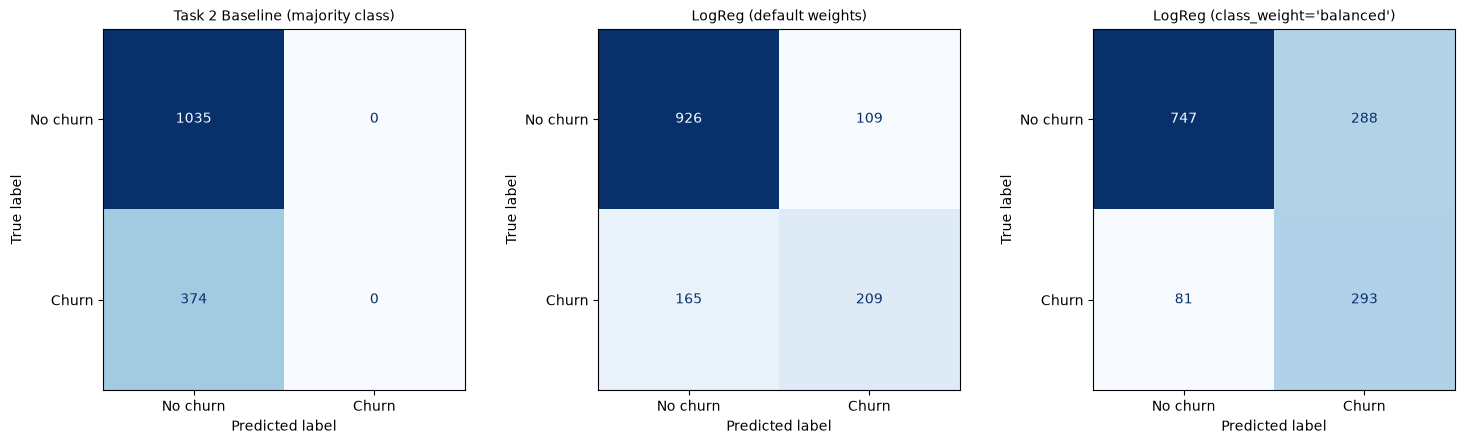

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for ax, (name, cm) in zip(axes, matrices.items()):
    ConfusionMatrixDisplay(cm, display_labels=["No churn", "Churn"]).plot(
        ax=ax, cmap="Blues", colorbar=False, values_format="d"
    )
    ax.set_title(name, fontsize=10)
plt.tight_layout()
plt.show()

## Threshold sweep

In [11]:
rows = []
for name in list(models)[1:]:
    for t in [0.30, 0.40, 0.50]:
        pred_t = (probas[name] >= t).astype(int)
        cm = confusion_matrix(y_test, pred_t)
        rows.append(
            {
                "model": name,
                "threshold": t,
                "precision": round(precision_score(y_test, pred_t, zero_division=0), 4),
                "recall": round(recall_score(y_test, pred_t, zero_division=0), 4),
                "f1": round(f1_score(y_test, pred_t, zero_division=0), 4),
                "FN (missed churners)": int(cm[1, 0]),
                "FP (false alarms)": int(cm[0, 1]),
            }
        )
pd.DataFrame(rows)

,model,threshold,precision,recall,f1,FN (missed churners),FP (false alarms)
0,LogReg (default weights),0.3,0.5193,0.7540,0.6150,92,261
1,LogReg (default weights),0.4,0.5682,0.6684,0.6143,124,190
2,LogReg (default weights),0.5,0.6572,0.5588,0.6040,165,109
3,LogReg (class_weight='balanced'),0.3,0.4295,0.9278,0.5871,27,461
4,LogReg (class_weight='balanced'),0.4,0.4662,0.8663,0.6062,50,371
5,LogReg (class_weight='balanced'),0.5,0.5043,0.7834,0.6136,81,288


## Feature effects (balanced model)

In [12]:
best = models["LogReg (class_weight='balanced')"]
names = best.named_steps["pre"].get_feature_names_out()
coefs = pd.Series(best.named_steps["clf"].coef_[0], index=names).sort_values()
print("Increase churn risk:")
print(coefs.tail(5).round(3).to_string())
print("\nReduce churn risk:")
print(coefs.head(5).round(3).to_string())

Increase churn risk:
cat__StreamingMovies_Yes            0.241
cat__PaperlessBilling_Yes           0.336
num__TotalCharges                   0.463
cat__Contract_Month-to-month        0.623
cat__InternetService_Fiber optic    0.674

Reduce churn risk:
num__tenure                               -1.131
cat__Contract_Two year                    -0.811
num__MonthlyCharges                       -0.673
cat__InternetService_DSL                  -0.660
cat__OnlineSecurity_No internet service   -0.312


## Business interpretation

The majority-class baseline reaches 73.5% accuracy by predicting "No" for everyone, but it finds no churners at all (recall 0, ROC-AUC 0.50). Both Logistic Regression models beat it clearly (ROC-AUC about 0.84).

Default weights give the best accuracy (80.6%) and precision (65.7%), but miss 165 of 374 churners (recall 55.9%). With `class_weight='balanced'`, recall rises to 78.3% and missed churners fall to 81, while false alarms rise from 109 to 288 and accuracy drops to 73.8%. ROC-AUC is almost unchanged, so class weighting moves the decision boundary rather than improving the ranking.

**Recommendation: deploy the balanced version.** It catches 84 more churners and adds 179 false alarms, so it pays off whenever one missed churner costs more than about 2.1 retention offers (179 / 84), which is very likely true for a subscription business. If retention offers are costly or the retention team has limited capacity, the default model, or a threshold near 0.40, is the more practical choice.

Short tenure, month-to-month contracts and fiber-optic internet raise churn risk, while long tenure and two-year contracts lower it.

*Numbers above come from `random_state=42` and may differ slightly if you change the split or library versions.*